# Predicting Employee Attrition - IBM HR Analytics

**Week 7 Graded Mini Project** - IITM Pravartak, Professional Certificate Programme in Generative AI and Machine Learning

**Goal:** predict whether an employee is likely to leave, and find out which factors drive attrition.

**Notebook outline**
1. Setup and data loading
2. Data understanding (EDA)
3. Data preprocessing (missing values, outliers, feature engineering, encoding, scaling)
4. Handling class imbalance
5. Model building and hyperparameter tuning (5 models)
6. Model evaluation (precision, recall, F1, ROC-AUC, PR-AUC, confusion matrices)
7. Decision threshold tuning and final model choice
8. Key attrition drivers
9. Save the final model
10. Summary and recommendations

## 1. Setup and data loading

In [1]:
# --- Standard data / plotting libraries ---
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# --- scikit-learn: splitting, preprocessing, models, metrics ---
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_val_score, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, classification_report)

# --- imbalanced-learn: SMOTE and a pipeline that applies it only during fit ---
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# --- Our own feature engineering (kept in a .py file so model.pkl can be reloaded) ---
from attrition_features import add_features, NOMINAL_COLS, DROP_COLS

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

# One seed everywhere -> same split, same SMOTE samples, same results on every run
SEED = 42

# Folder for charts and result tables (used later in the report)
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

In [2]:
# Load the Kaggle CSV (kept next to this notebook)
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
print("Shape:", df.shape)
df.head()

Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
# Column types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

## 2. Data understanding (EDA)

### 2.1 Data quality checks

In [4]:
# Missing values and duplicate rows
print("Missing values in total:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

# Columns where every row has the same value carry no information
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns:", constant_cols)
print("EmployeeNumber unique values:", df["EmployeeNumber"].nunique(), "of", len(df), "-> it is an ID")

Missing values in total: 0
Duplicate rows: 0
Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
EmployeeNumber unique values: 1470 of 1470 -> it is an ID


**Observations**
- No missing values and no duplicates, so no imputation is needed. The pipeline still uses encoders that tolerate unseen categories, so the saved model won't crash on new data.
- `EmployeeCount`, `Over18` and `StandardHours` are constant and `EmployeeNumber` is an ID. All four are dropped inside `add_features`.

### 2.2 Target distribution - how imbalanced is it?

           count  percent
Attrition                
No          1233     83.9
Yes          237     16.1


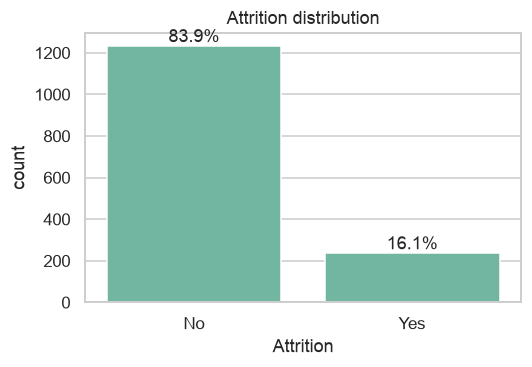

In [5]:
counts = df["Attrition"].value_counts()
pct = df["Attrition"].value_counts(normalize=True).mul(100).round(1)
print(pd.DataFrame({"count": counts, "percent": pct}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="Attrition", order=["No", "Yes"], ax=ax)
for p, v in zip(ax.patches, pct[["No", "Yes"]]):
    ax.annotate(f"{v}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Attrition distribution")
plt.tight_layout(); plt.savefig(OUT / "01_target_distribution.png"); plt.show()

Only **16.1%** of employees left (237 of 1,470), so the classes are imbalanced about 5:1.
A model that always predicts "No" would already score **83.9% accuracy** while catching nobody. That's why accuracy is not used as the main metric. We focus on **recall, precision, F1 and ROC-AUC** for the "Yes" class.

### 2.3 Attrition rate across categorical features

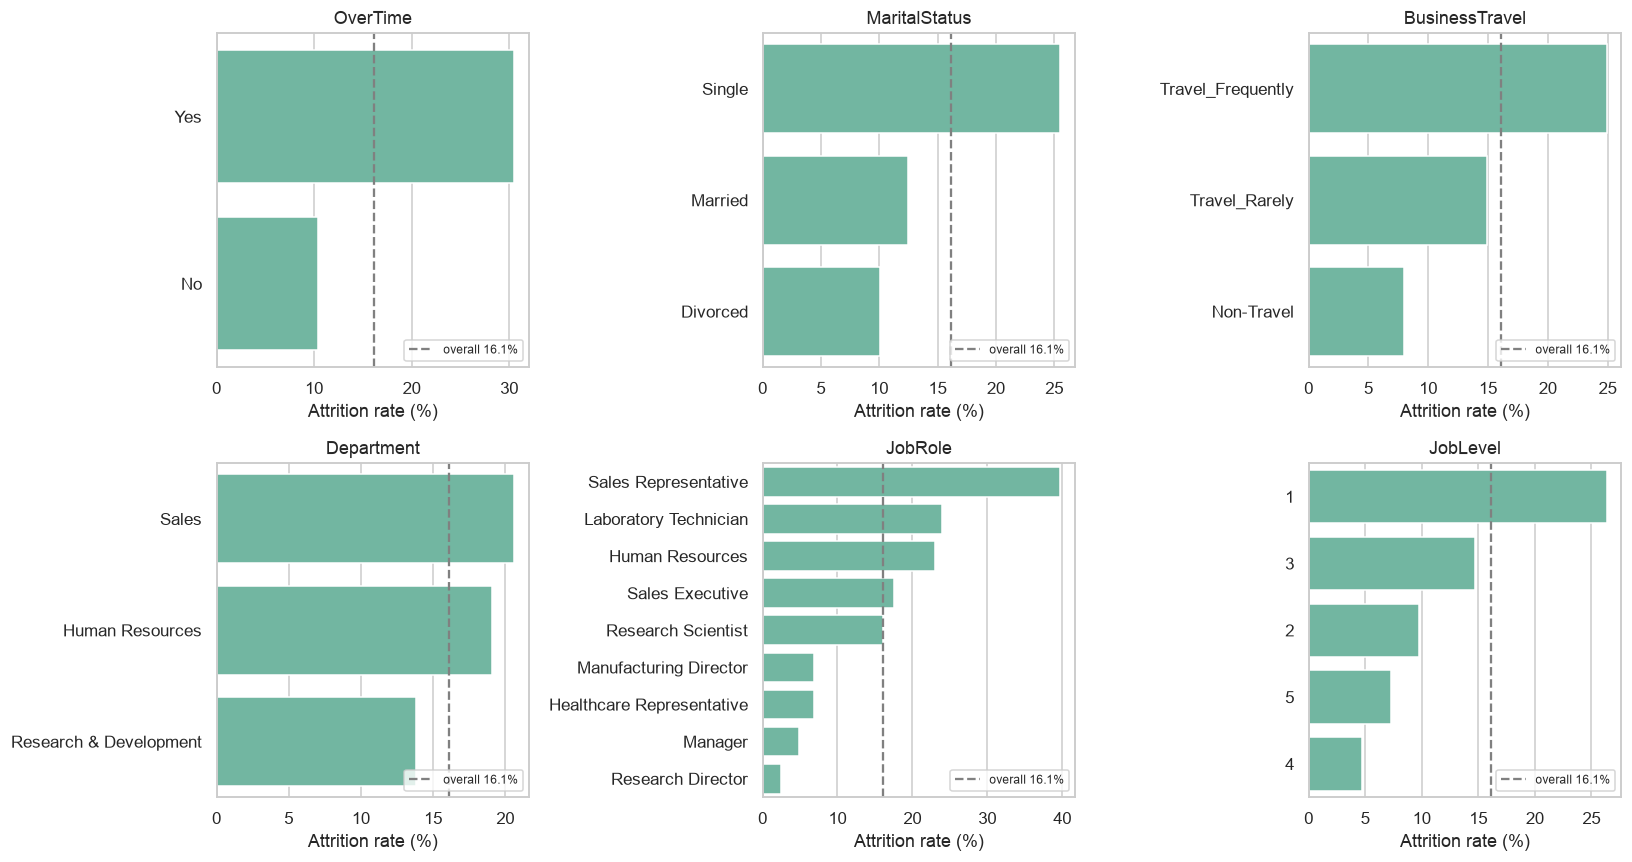

In [6]:
# Attrition as 0/1 makes "mean" = attrition rate
df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)

cat_view = ["OverTime", "MaritalStatus", "BusinessTravel", "Department", "JobRole", "JobLevel"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cat_view):
    rate = df.groupby(col)["AttritionFlag"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index.astype(str), ax=ax, color="#66c2a5")
    ax.axvline(df["AttritionFlag"].mean() * 100, ls="--", c="grey", label="overall 16.1%")
    ax.set_xlabel("Attrition rate (%)"); ax.set_ylabel(""); ax.set_title(col)
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "02_attrition_by_category.png"); plt.show()

In [7]:
# The same numbers as a table, for the strongest categorical signals
for col in ["OverTime", "MaritalStatus", "BusinessTravel", "JobLevel"]:
    print(df.groupby(col)["AttritionFlag"].agg(rate="mean", employees="count")
            .assign(rate=lambda t: (t["rate"] * 100).round(1)), "\n")

          rate  employees
OverTime                 
No        10.4       1054
Yes       30.5        416 

               rate  employees
MaritalStatus                 
Divorced       10.1        327
Married        12.5        673
Single         25.5        470 

                   rate  employees
BusinessTravel                    
Non-Travel          8.0        150
Travel_Frequently  24.9        277
Travel_Rarely      15.0       1043 

          rate  employees
JobLevel                 
1         26.3        543
2          9.7        534
3         14.7        218
4          4.7        106
5          7.2         69 



**What stands out**
- **OverTime** is the clearest signal. People working overtime leave at about **30.5%**, roughly 3x the 10.4% rate of those who don't.
- **Single** employees leave at about 25.5%, against roughly 10-12% for married or divorced employees.
- **Frequent travellers** (24.9%) leave far more often than those who don't travel (8%).
- **Sales Representatives** (about 40%) and **Laboratory Technicians / HR** are the riskiest roles. Managers and Research Directors rarely leave.
- **Job level 1** (entry level) has by far the highest rate, about 26%.

### 2.4 Numeric features: leavers vs stayers

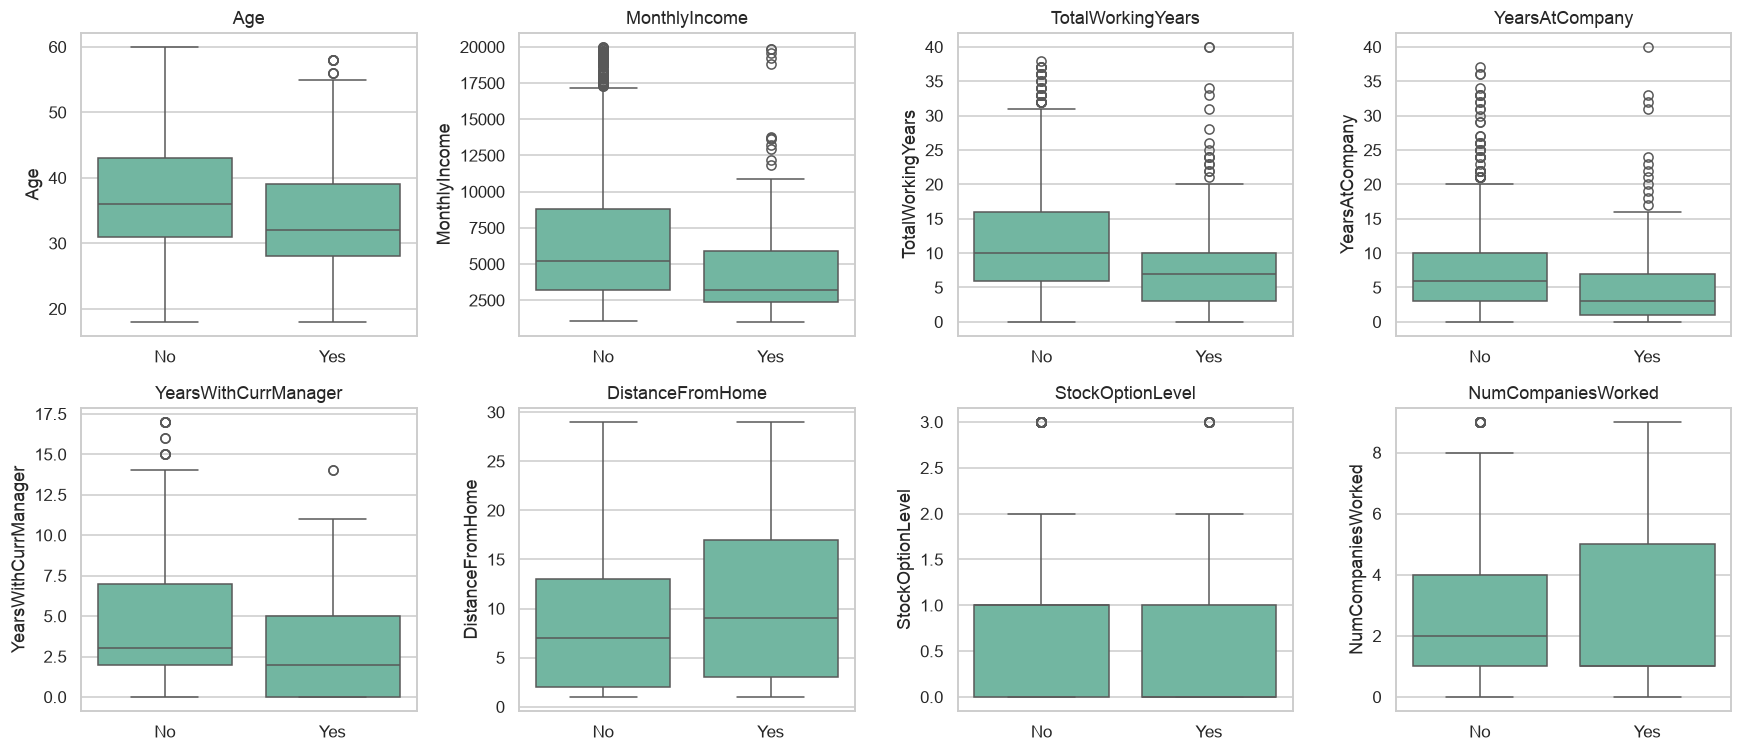

Attrition,No,Yes
Age,36.0,32.0
MonthlyIncome,5204.0,3202.0
TotalWorkingYears,10.0,7.0
YearsAtCompany,6.0,3.0
YearsWithCurrManager,3.0,2.0
DistanceFromHome,7.0,9.0
StockOptionLevel,1.0,0.0
NumCompaniesWorked,2.0,1.0


In [8]:
num_view = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
            "YearsWithCurrManager", "DistanceFromHome", "StockOptionLevel", "NumCompaniesWorked"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_view):
    sns.boxplot(data=df, x="Attrition", y=col, order=["No", "Yes"], ax=ax)
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(OUT / "03_numeric_boxplots.png"); plt.show()

# Medians side by side
df.groupby("Attrition")[num_view].median().T

Leavers are typically **younger** (median 32 vs 36), **earn less** (median income about 3,200 vs 5,200), have **fewer total working years** and **shorter tenure**, and live **slightly further** from work.
Most of these features move together (age, income, experience and tenure), so the story is really about **early-career, lower-paid employees**.

### 2.5 Satisfaction and work-life ratings

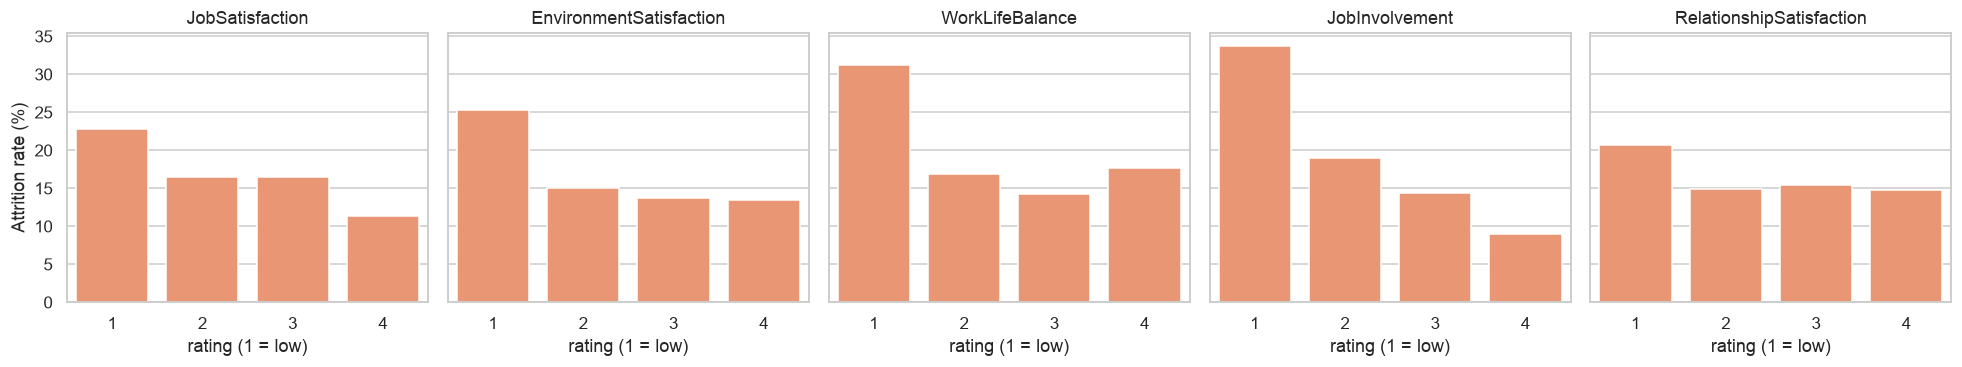

In [9]:
sat_cols = ["JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance",
            "JobInvolvement", "RelationshipSatisfaction"]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)
for ax, col in zip(axes, sat_cols):
    rate = df.groupby(col)["AttritionFlag"].mean() * 100
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color="#fc8d62")
    ax.set_title(col); ax.set_xlabel("rating (1 = low)"); ax.set_ylabel("Attrition rate (%)")
plt.tight_layout(); plt.savefig(OUT / "04_satisfaction.png"); plt.show()

For every rating, the lowest score (1) has the highest attrition:
- **JobInvolvement:** 33.7% at rating 1 against 9.0% at rating 4. This is the steepest drop.
- **WorkLifeBalance:** 31.2% at rating 1. Interestingly, it rises again slightly at rating 4.
- **EnvironmentSatisfaction:** 25.4% at rating 1 against 13.5% at rating 4.
- **JobSatisfaction:** 22.8% at rating 1 against 11.3% at rating 4.
- **RelationshipSatisfaction** shows only a weak effect.
These ratings are ordered (1 < 2 < 3 < 4), so they're kept as numbers rather than one-hot encoded.

### 2.6 Correlation between numeric features

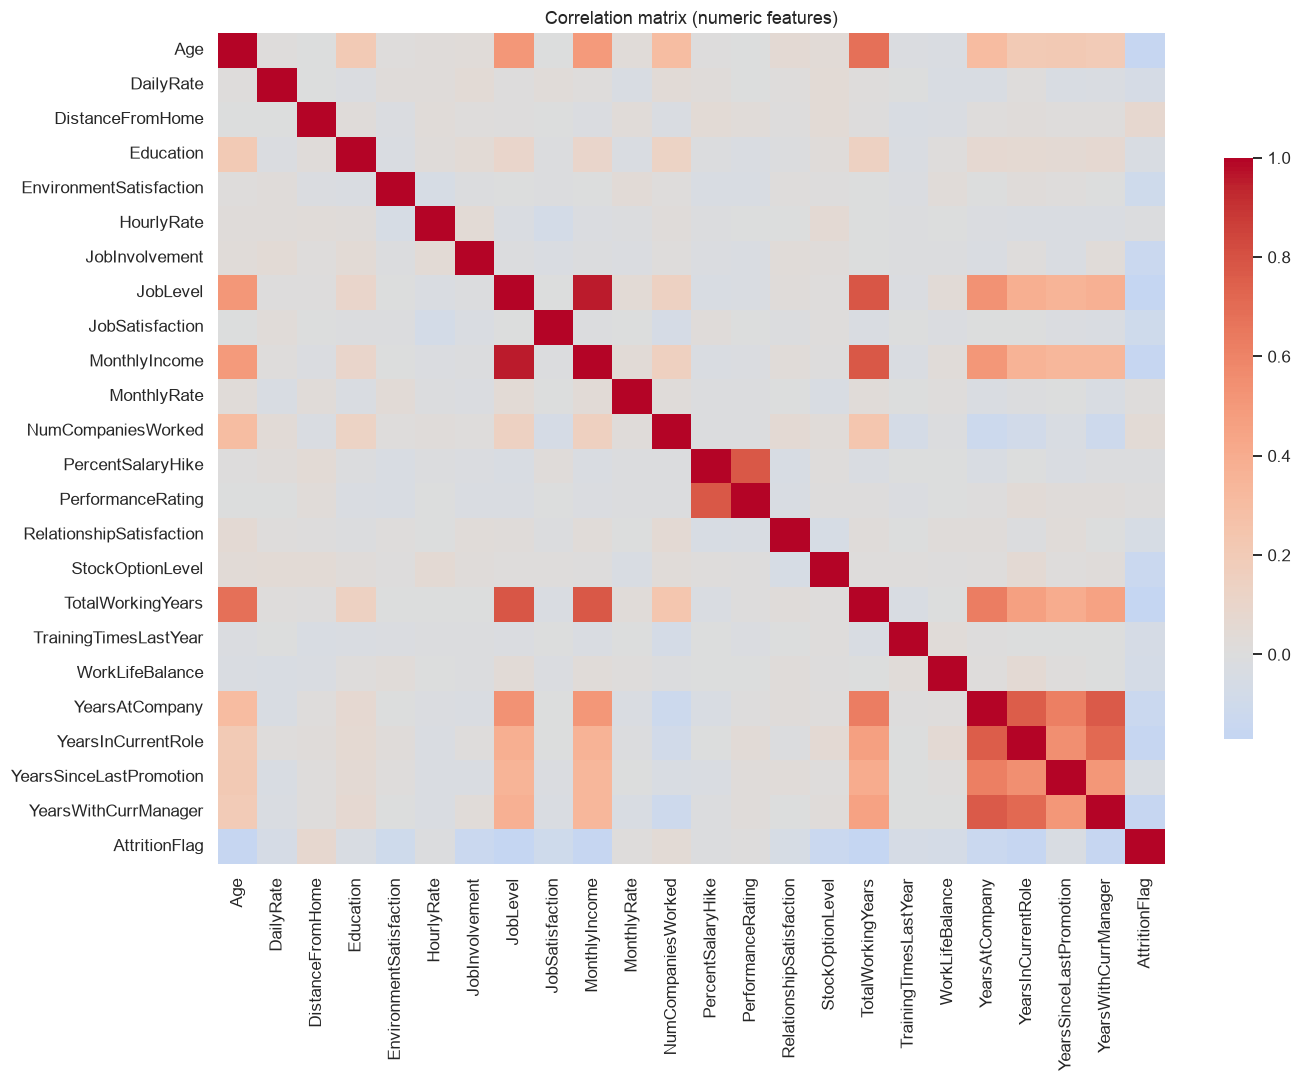

Strongest pairs:
 JobLevel            MonthlyIncome           0.95
                    TotalWorkingYears       0.78
PercentSalaryHike   PerformanceRating       0.77
MonthlyIncome       TotalWorkingYears       0.77
YearsAtCompany      YearsWithCurrManager    0.77
                    YearsInCurrentRole      0.76
YearsInCurrentRole  YearsWithCurrManager    0.71
Age                 TotalWorkingYears       0.68
dtype: float64

Correlation with AttritionFlag:
 TotalWorkingYears      -0.17
JobLevel               -0.17
YearsInCurrentRole     -0.16
MonthlyIncome          -0.16
Age                    -0.16
YearsWithCurrManager   -0.16
StockOptionLevel       -0.14
YearsAtCompany         -0.13
Name: AttritionFlag, dtype: float64


In [10]:
num_cols_all = df.select_dtypes("number").drop(columns=["EmployeeCount", "StandardHours", "EmployeeNumber"]).columns
corr = df[num_cols_all].corr()

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Correlation matrix (numeric features)")
plt.tight_layout(); plt.savefig(OUT / "05_correlation.png"); plt.show()

# Most correlated pairs (excluding the diagonal)
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .sort_values(key=abs, ascending=False))
print("Strongest pairs:\n", pairs.head(8).round(2))
print("\nCorrelation with AttritionFlag:\n", corr["AttritionFlag"].drop("AttritionFlag").sort_values().round(2).head(8))

- `JobLevel` and `MonthlyIncome` are almost the same variable (r = 0.95), and `TotalWorkingYears` is strongly tied to both. This multicollinearity makes individual logistic regression coefficients less stable. Regularisation (the `C` parameter) is tuned partly to handle it, and the driver analysis uses **permutation importance** as a cross-check.
- No single numeric feature has a large linear correlation with attrition (all |r| < 0.18). Attrition comes from a **combination** of factors, which is why multivariate models are needed.

## 3. Data preprocessing

### 3.1 Outlier check (IQR rule)

In [11]:
# Count values outside 1.5 * IQR for each numeric column
outlier_counts = {}
for col in num_cols_all.drop("AttritionFlag"):
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    if n:
        outlier_counts[col] = int(n)
print(pd.Series(outlier_counts, name="outliers").sort_values(ascending=False))

TrainingTimesLastYear      238
PerformanceRating          226
MonthlyIncome              114
YearsSinceLastPromotion    107
YearsAtCompany             104
StockOptionLevel            85
TotalWorkingYears           63
NumCompaniesWorked          52
YearsInCurrentRole          21
YearsWithCurrManager        14
Name: outliers, dtype: int64


Two groups show up:
- `TrainingTimesLastYear` and `PerformanceRating` are flagged only because they take a few discrete values with a narrow IQR. For example, `PerformanceRating` is only ever 3 or 4, so every "4" counts as an "outlier". These are **not real outliers**.
- `MonthlyIncome`, `YearsSinceLastPromotion`, `YearsAtCompany`, `TotalWorkingYears` and `StockOptionLevel` are **right-skewed but genuine**. A senior person earning 19,000 a month or someone with 40 years of service is real data, not an error.

**Decision:** keep the rows rather than delete about 10% of a small dataset.
- Tree models don't care about extreme values.
- For logistic regression and SVM, the values are standardised, and the models are regularised (C is tuned), which limits the pull of extreme points.
- Rows that are both outliers *and* leavers carry information about the minority class, which we can't afford to lose.

### 3.2 Feature engineering

Defined in `attrition_features.py` so the exact same steps run at training time and when the saved model is used later:

| New feature | Formula | Why it might help |
|---|---|---|
| `AvgSatisfaction` | mean of Environment, Job, Relationship satisfaction and WorkLifeBalance | one combined "how happy" score, less noisy than any single rating |
| `TenureRatio` | YearsAtCompany / (TotalWorkingYears + 1) | how much of the career is spent here, a loyalty signal |
| `YearsPerCompany` | TotalWorkingYears / (NumCompaniesWorked + 1) | low = job hopper |
| `PromotionStagnation` | YearsSinceLastPromotion / (YearsAtCompany + 1) | stuck without a promotion |
| `IncomeVsLevel` | MonthlyIncome / median income of that JobLevel | paid below peers at the same level |

In [12]:
X_raw = df.drop(columns=["Attrition", "AttritionFlag"])
y = df["AttritionFlag"]

# Quick look at the engineered features vs attrition
fe = add_features(X_raw)
new_cols = ["AvgSatisfaction", "TenureRatio", "YearsPerCompany", "PromotionStagnation", "IncomeVsLevel"]
fe.assign(Attrition=df["Attrition"]).groupby("Attrition")[new_cols].median().round(3)

,AvgSatisfaction,TenureRatio,YearsPerCompany,PromotionStagnation,IncomeVsLevel
Attrition,,,,,
No,2.75,0.667,3.333,0.143,1.006
Yes,2.50,0.500,1.625,0.125,0.964


Leavers have a lower average satisfaction, have spent a smaller share of their career at the company, and are paid a little less than peers at the same level. The new features carry signal.

### 3.3 Train / test split

Stratified 80/20 split, so both parts keep the 16% attrition rate. The test set is **not touched** until final evaluation. All tuning uses cross-validation on the training set only.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_train.shape, " attrition rate = %.3f" % y_train.mean())
print("Test: ", X_test.shape, " attrition rate = %.3f" % y_test.mean())

# The IncomeVsLevel feature uses a fixed table of median income per JobLevel.
# Check that the training-only medians match the table in attrition_features.py
from attrition_features import LEVEL_MEDIAN_INCOME
print("Train medians:", X_train.groupby("JobLevel")["MonthlyIncome"].median().to_dict())
print("Table used   :", LEVEL_MEDIAN_INCOME)

Train: (1176, 34)  attrition rate = 0.162
Test:  (294, 34)  attrition rate = 0.160
Train medians: {1: 2658.0, 2: 5346.5, 3: 9985.0, 4: 16207.5, 5: 19197.0}
Table used   : {1: 2658.0, 2: 5346.5, 3: 9985.0, 4: 16207.5, 5: 19197.0}


### 3.4 Encoding and scaling

- **Nominal text columns** (`OverTime`, `JobRole`, `Department`, etc.) use **one-hot encoding**. `drop="if_binary"` turns Yes/No columns into a single 0/1 column, and `handle_unknown="ignore"` protects the saved model from unseen categories.
- **Numeric and ordinal columns** (ratings 1-4, levels, years, income) use **StandardScaler**. Scaling is required for logistic regression and SVM. It does no harm to tree models, so one shared preprocessor keeps the pipeline simple.

Everything is wrapped in a single pipeline: `add_features -> ColumnTransformer -> (SMOTE) -> model`. Because the scaler and SMOTE sit *inside* the pipeline, they are re-fitted on each training fold during cross-validation. **No information leaks from validation or test rows.**

In [14]:
num_features = [c for c in fe.columns if c not in NOMINAL_COLS]

def prep_steps():
    # The two preprocessing steps every model pipeline starts with.
    # Returned as a list (not a nested Pipeline) because imbalanced-learn's
    # Pipeline does not allow another Pipeline as an intermediate step.
    return [
        ("features", FunctionTransformer(add_features)),
        ("prep", ColumnTransformer([
            ("num", StandardScaler(), num_features),
            ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), NOMINAL_COLS),
        ])),
    ]

prep_check = Pipeline(prep_steps()).fit(X_train)
print("Numeric features:", len(num_features))
print("Total features after encoding:", prep_check.transform(X_train.head()).shape[1])

Numeric features: 28
Total features after encoding: 54


## 4. Handling class imbalance

Three options compared on a plain logistic regression with 5-fold stratified cross-validation (training data only):
1. **Do nothing** (baseline)
2. **Class weights** (`class_weight="balanced"`): mistakes on leavers cost about 5x more during training
3. **SMOTE**: creates synthetic leaver rows *inside each training fold only*

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["recall", "precision", "f1", "roc_auc"]

def cv_summary(pipe):
    from sklearn.model_selection import cross_validate
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    return {m: r[f"test_{m}"].mean() for m in scoring}

imb = pd.DataFrame({
    "No handling": cv_summary(Pipeline([*prep_steps(),
                                        ("clf", LogisticRegression(max_iter=2000))])),
    "Class weights": cv_summary(Pipeline([*prep_steps(),
                                          ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])),
    "SMOTE": cv_summary(Pipeline([*prep_steps(), ("smote", SMOTE(random_state=SEED)),
                                  ("clf", LogisticRegression(max_iter=2000))])),
}).T.round(3)
imb.to_csv(OUT / "imbalance_comparison.csv")
imb

,recall,precision,f1,roc_auc
No handling,0.474,0.769,0.584,0.845
Class weights,0.737,0.378,0.499,0.832
SMOTE,0.726,0.408,0.521,0.837


Without any handling, the model catches **fewer than half of the leavers** (recall 0.47).
Class weights and SMOTE push recall up to about **0.72-0.74**. In exchange, precision drops, and at the default 0.5 cut-off F1 actually goes *down* (0.58 to about 0.50-0.52). ROC-AUC barely moves (0.83-0.85). This shows that imbalance handling does not make the model *rank* people better. It shifts the probabilities upward, so the 0.5 cut-off now sits in the wrong place for a precision/recall balance. Two conclusions:
1. For HR, a missed leaver costs more than a false alarm, so the gain in recall is worth having.
2. The decision threshold has to be tuned after training (Section 7). Otherwise the comparison between methods is unfair.

**Decision for the model comparison:**
- Models that support it (Logistic Regression, Decision Tree, Random Forest, SVM) use `class_weight="balanced"`. It's simple, adds no synthetic rows and performed as well as SMOTE here.
- **Gradient Boosting** has no `class_weight` option, so it uses **SMOTE** inside the pipeline.

## 5. Model building and hyperparameter tuning

Five classifiers, covering linear, distance/kernel-based and tree-based families:

| Model | Type | Why include it |
|---|---|---|
| Logistic Regression | linear | interpretable baseline, coefficients = drivers |
| Decision Tree | non-linear | easy-to-explain rules |
| Random Forest | non-linear ensemble | reduces the high variance of a single tree |
| SVM (RBF kernel) | non-linear kernel | strong on small, scaled tabular data |
| Gradient Boosting | non-linear ensemble | often the strongest model on tabular data |

Each model is tuned with **GridSearchCV + 5-fold stratified CV**, optimising **F1 on the "Yes" class**. F1 balances catching leavers (recall) against not flooding HR with false alarms (precision). ROC-AUC is recorded too.

In [16]:
models = {
    "Logistic Regression": (
        Pipeline([*prep_steps(),
                  ("clf", LogisticRegression(max_iter=5000, class_weight="balanced", solver="liblinear"))]),
        {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3], "clf__penalty": ["l1", "l2"]}),
    "Decision Tree": (
        Pipeline([*prep_steps(),
                  ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=SEED))]),
        {"clf__max_depth": [3, 4, 5, 6, 8], "clf__min_samples_leaf": [5, 10, 20, 40],
         "clf__criterion": ["gini", "entropy"]}),
    "Random Forest": (
        Pipeline([*prep_steps(),
                  ("clf", RandomForestClassifier(class_weight="balanced_subsample", random_state=SEED, n_jobs=-1))]),
        {"clf__n_estimators": [300], "clf__max_depth": [4, 6, 8, None],
         "clf__min_samples_leaf": [3, 5, 10], "clf__max_features": ["sqrt", 0.3]}),
    "SVM (RBF)": (
        Pipeline([*prep_steps(),
                  ("clf", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED))]),
        {"clf__C": [0.1, 0.3, 1, 3, 10], "clf__gamma": ["scale", 0.003, 0.01, 0.03]}),
    "Gradient Boosting + SMOTE": (
        Pipeline([*prep_steps(), ("smote", SMOTE(random_state=SEED)),
                  ("clf", GradientBoostingClassifier(random_state=SEED))]),
        {"clf__n_estimators": [100, 300], "clf__learning_rate": [0.03, 0.1],
         "clf__max_depth": [2, 3], "clf__subsample": [0.8, 1.0]}),
}

searches = {}
for name, (pipe, grid) in models.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring={"f1": "f1", "roc_auc": "roc_auc"},
                      refit="f1", n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    best = gs.cv_results_
    i = gs.best_index_
    print(f"{name:28s} CV F1 = {best['mean_test_f1'][i]:.3f}  CV ROC-AUC = {best['mean_test_roc_auc'][i]:.3f}")
    print(f"{'':28s} best params: { {k.replace('clf__', ''): v for k, v in gs.best_params_.items()} }")

Logistic Regression          CV F1 = 0.507  CV ROC-AUC = 0.834
                             best params: {'C': 0.1, 'penalty': 'l2'}


Decision Tree                CV F1 = 0.425  CV ROC-AUC = 0.707
                             best params: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 20}


Random Forest                CV F1 = 0.491  CV ROC-AUC = 0.789
                             best params: {'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 300}


SVM (RBF)                    CV F1 = 0.551  CV ROC-AUC = 0.842
                             best params: {'C': 10, 'gamma': 0.003}


Gradient Boosting + SMOTE    CV F1 = 0.551  CV ROC-AUC = 0.825
                             best params: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}


In [17]:
cv_table = pd.DataFrame({
    name: {"CV F1": gs.cv_results_["mean_test_f1"][gs.best_index_],
           "CV F1 std": gs.cv_results_["std_test_f1"][gs.best_index_],
           "CV ROC-AUC": gs.cv_results_["mean_test_roc_auc"][gs.best_index_]}
    for name, gs in searches.items()}).T.round(3).sort_values("CV F1", ascending=False)
cv_table.to_csv(OUT / "cv_results.csv")
cv_table

,CV F1,CV F1 std,CV ROC-AUC
SVM (RBF),0.551,0.041,0.842
Gradient Boosting + SMOTE,0.551,0.056,0.825
Logistic Regression,0.507,0.045,0.834
Random Forest,0.491,0.036,0.789
Decision Tree,0.425,0.025,0.707


**Notes on the tuning**
- **SVM (RBF)** and **Gradient Boosting + SMOTE** have the highest CV F1 (about 0.55). Gradient Boosting is a little less stable across folds (std 0.056 vs 0.041).
- **Logistic Regression** picked moderate L2 regularisation (`C = 0.1`). That's consistent with the correlated income/level/experience features seen in the heatmap. It has the second-best CV ROC-AUC (0.834 vs 0.842 for SVM).
- **Random Forest** chose shallow trees (depth 4) and is clearly behind on ROC-AUC (0.79).
- **The single Decision Tree is the weakest model** (ROC-AUC 0.71). It needed depth 3 and at least 20 samples per leaf to avoid overfitting, and that leaves it too simple to rank people well.
- The CV F1 values here are all measured at the default 0.5 cut-off, which, as Section 4 showed, is not the right cut-off for weighted models. The final comparison is done after threshold tuning.

## 6. Model evaluation on the held-out test set

In [18]:
rows, probas = [], {}
for name, gs in searches.items():
    p = gs.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[name] = p
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, p),
                 "PR-AUC": average_precision_score(y_test, p)})
test_table = pd.DataFrame(rows).set_index("Model").round(3).sort_values("F1", ascending=False)
test_table.to_csv(OUT / "test_results.csv")
test_table

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.762,0.361,0.638,0.462,0.801,0.572
Random Forest,0.793,0.391,0.532,0.450,0.755,0.376
Gradient Boosting + SMOTE,0.857,0.600,0.319,0.417,0.785,0.526
SVM (RBF),0.864,0.684,0.277,0.394,0.805,0.560
Decision Tree,0.741,0.307,0.489,0.377,0.683,0.272


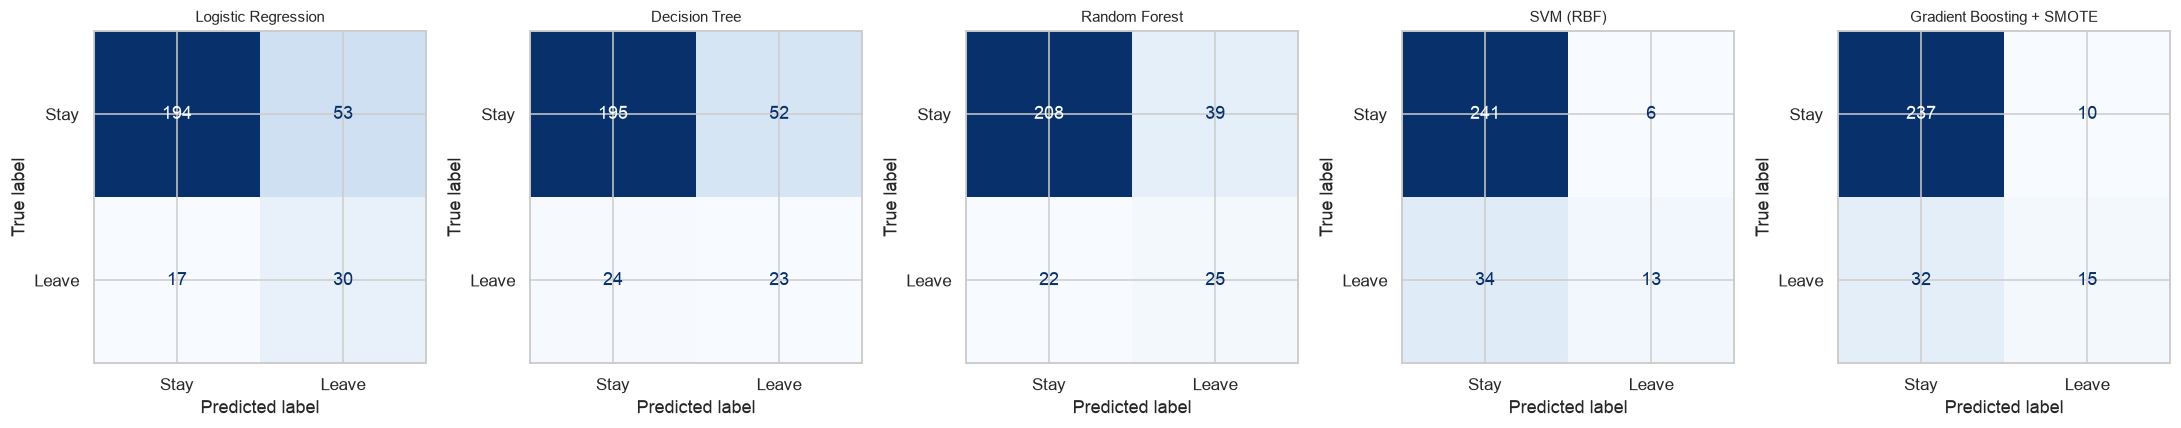

In [19]:
# Confusion matrices: rows = actual, columns = predicted
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, (name, p) in zip(axes, probas.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p >= .5).astype(int)),
                           display_labels=["Stay", "Leave"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "06_confusion_matrices.png"); plt.show()

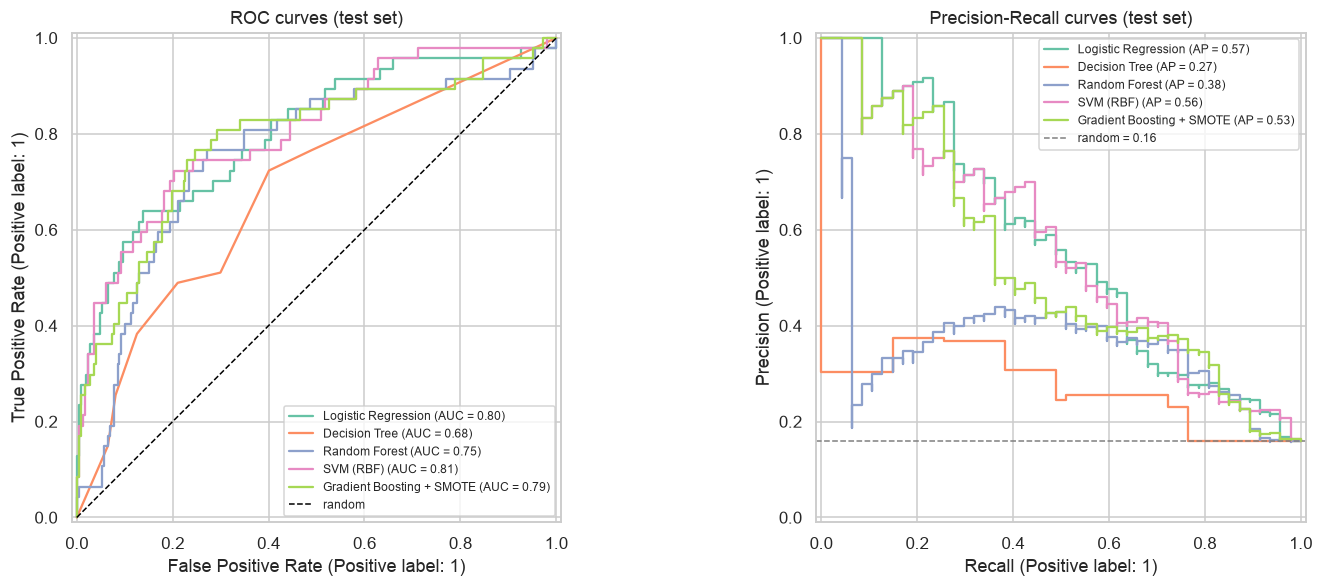

In [20]:
# ROC curves (ranking quality) and Precision-Recall curves (better for imbalanced data)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
for name, p in probas.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=ax1)
    PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=ax2)
ax1.plot([0, 1], [0, 1], "k--", lw=1, label="random")
ax1.set_title("ROC curves (test set)")
ax2.axhline(y_test.mean(), ls="--", c="grey", lw=1, label=f"random = {y_test.mean():.2f}")
ax2.set_title("Precision-Recall curves (test set)")
ax1.legend(fontsize=8); ax2.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "07_roc_pr_curves.png"); plt.show()

**How to read the metrics (HR view)**
- **Recall (Yes):** of the people who actually left, how many did we flag? A missed leaver means a surprise resignation and a replacement cost, which is often estimated at 6-9 months of salary.
- **Precision (Yes):** of the people we flagged, how many really left? Low precision means HR spends retention effort (conversations, raises) on people who were going to stay anyway.
- **F1** balances the two and is our main selection metric.
- **ROC-AUC** measures how well the model *ranks* employees by risk, independent of the threshold. **PR-AUC** is the stricter version for imbalanced data: a random model scores about 0.16 here, not 0.5.
- **Accuracy** is shown only for completeness. The "always No" model already gets about 84%.

**Why the 0.5 results look so different between models:** at the default 0.5 cut-off, SVM and Gradient Boosting look "careful" (high precision, low recall), while Logistic Regression and the trees flag many more people. This is mostly a **threshold effect, not a quality difference**. SVM's probabilities come from Platt scaling, which partly undoes the class weighting. SMOTE and class weights also shift probabilities by different amounts. The ROC-AUC and PR-AUC columns, which don't depend on the threshold, show that LR, SVM and Gradient Boosting rank employees about equally well. To compare fairly, each model gets its own tuned threshold in the next section.

## 7. Decision threshold tuning (per model) and final model choice

For each model, out-of-fold probabilities are produced on the **training set** with 5-fold CV. Every training row is scored by a model that didn't see it. We then pick the threshold that maximises F1. The test set is still unseen at this point, so the test scores below stay an honest estimate.

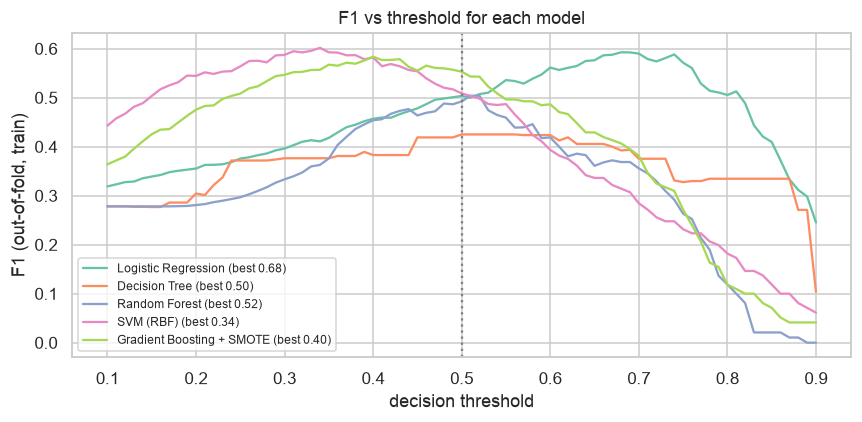

,Threshold,OOF F1 (train),Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,,
SVM (RBF),0.34,0.602,0.535,0.489,0.511,0.805,0.560
Logistic Regression,0.68,0.593,0.575,0.489,0.529,0.801,0.572
Gradient Boosting + SMOTE,0.40,0.584,0.458,0.468,0.463,0.785,0.526
Random Forest,0.52,0.504,0.426,0.489,0.455,0.755,0.376
Decision Tree,0.50,0.425,0.307,0.489,0.377,0.683,0.272


In [21]:
thresholds = np.arange(0.10, 0.91, 0.01)
tuned_rows, best_thr, f1_curves = [], {}, {}

for name, gs in searches.items():
    # Probabilities each training row gets from a model that did NOT see it (5-fold)
    oof = cross_val_predict(gs.best_estimator_, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    f1s = np.array([f1_score(y_train, (oof >= t).astype(int)) for t in thresholds])
    t = float(thresholds[f1s.argmax()])
    best_thr[name], f1_curves[name] = t, f1s

    # Apply that threshold to the untouched test set
    pred = (probas[name] >= t).astype(int)
    tuned_rows.append({"Model": name, "Threshold": round(t, 2), "OOF F1 (train)": f1s.max(),
                       "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                       "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, probas[name]),
                       "PR-AUC": average_precision_score(y_test, probas[name])})

tuned_table = pd.DataFrame(tuned_rows).set_index("Model").round(3).sort_values("OOF F1 (train)", ascending=False)
tuned_table.to_csv(OUT / "tuned_threshold_results.csv")

fig, ax = plt.subplots(figsize=(8, 4))
for name, f1s in f1_curves.items():
    ax.plot(thresholds, f1s, label=f"{name} (best {best_thr[name]:.2f})")
ax.axvline(0.5, ls=":", c="grey")
ax.set_xlabel("decision threshold"); ax.set_ylabel("F1 (out-of-fold, train)")
ax.set_title("F1 vs threshold for each model"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "08_threshold.png"); plt.show()
tuned_table

**Final model choice: Logistic Regression**

- After threshold tuning, **SVM and Logistic Regression are effectively tied** on the training data (OOF F1 0.602 vs 0.593). The difference is far smaller than the fold-to-fold variation (about ±0.04).
- On the untouched test set, Logistic Regression has the **best F1 (0.53) and best PR-AUC (0.57)**, with ROC-AUC (0.80) equal to SVM's. So the test set confirms the choice rather than driving it.
- Since performance is a tie, the tie-breakers decide:
  - **Explainability:** HR can see *why* someone is flagged (coefficients and odds ratios), which an RBF SVM can't offer directly.
  - **Stability:** low CV std.
  - **Simplicity:** a small, fast model with nothing exotic to maintain.
- Gradient Boosting, Random Forest and the Decision Tree are behind on every threshold-free metric.

With the tuned threshold of 0.68, the final model flags 40 of the 294 test employees. 23 of them actually left (precision 0.58), and it catches 23 of the 47 leavers (recall 0.49).

In [22]:
final_name = "Logistic Regression"
final_model = searches[final_name].best_estimator_
best_t = best_thr[final_name]
p_test = probas[final_name]
compare = []
for label, t in [("default 0.50", 0.5), (f"tuned {best_t:.2f}", best_t)]:
    pred = (p_test >= t).astype(int)
    compare.append({"Threshold": label,
                    "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                    "F1": f1_score(y_test, pred), "Flagged": int(pred.sum()),
                    "Leavers caught": f"{int(((pred == 1) & (y_test == 1)).sum())} / {int(y_test.sum())}"})
thr_table = pd.DataFrame(compare).set_index("Threshold").round(3)
thr_table.to_csv(OUT / "threshold_comparison.csv")
print(classification_report(y_test, (p_test >= best_t).astype(int), target_names=["Stay", "Leave"]))
thr_table

              precision    recall  f1-score   support

        Stay       0.91      0.93      0.92       247
       Leave       0.57      0.49      0.53        47

    accuracy                           0.86       294
   macro avg       0.74      0.71      0.72       294
weighted avg       0.85      0.86      0.86       294



,Precision,Recall,F1,Flagged,Leavers caught
Threshold,,,,,
default 0.50,0.361,0.638,0.462,83,30 / 47
tuned 0.68,0.575,0.489,0.529,40,23 / 47


The threshold is a **business lever**, not just a technical setting:
- If HR's retention actions are cheap (a check-in conversation), use a **lower** threshold to catch more leavers.
- If the actions are expensive (counter-offers), use a **higher** threshold so fewer people are flagged, but they are more certain.

The saved model metadata stores the tuned threshold. The README shows how to change it.

## 8. Key attrition drivers

Two complementary views:
1. **Logistic regression coefficients** give the direction and size of each effect (features are standardised, so they're comparable). Converted to **odds ratios**: >1 means higher risk, <1 means lower risk.
2. **Permutation importance** on the test set: how much does ROC-AUC drop when one original column is shuffled? This is model-agnostic and works on the *raw* columns, which avoids splitting a feature's effect across its one-hot pieces.

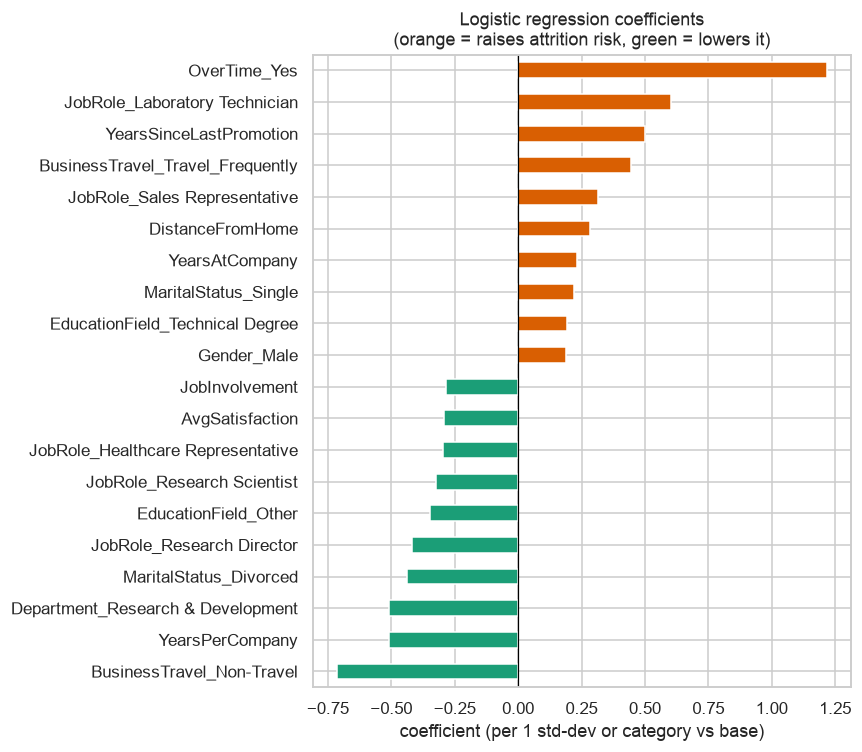

,coef,odds_ratio
OverTime_Yes,1.22,3.38
BusinessTravel_Non-Travel,-0.71,0.49
JobRole_Laboratory Technician,0.60,1.82
YearsPerCompany,-0.51,0.60
Department_Research & Development,-0.51,0.60
YearsSinceLastPromotion,0.50,1.65
BusinessTravel_Travel_Frequently,0.44,1.56
MaritalStatus_Divorced,-0.44,0.65
JobRole_Research Director,-0.42,0.66
EducationField_Other,-0.35,0.71


In [23]:
# Coefficients always come from the tuned logistic regression (the explainable model)
lr_model = searches["Logistic Regression"].best_estimator_
feat_names = lr_model.named_steps["prep"].get_feature_names_out()
feat_names = [f.split("__", 1)[1] for f in feat_names]
coefs = pd.Series(lr_model.named_steps["clf"].coef_[0], index=feat_names)

top = pd.concat([coefs.sort_values().head(10), coefs.sort_values().tail(10)])
fig, ax = plt.subplots(figsize=(8, 7))
top.plot.barh(ax=ax, color=["#1b9e77" if v < 0 else "#d95f02" for v in top])
ax.axvline(0, c="k", lw=.8)
ax.set_title("Logistic regression coefficients\n(orange = raises attrition risk, green = lowers it)")
ax.set_xlabel("coefficient (per 1 std-dev or category vs base)")
plt.tight_layout(); plt.savefig(OUT / "09_lr_coefficients.png"); plt.show()

odds = (pd.DataFrame({"coef": coefs, "odds_ratio": np.exp(coefs)})
          .reindex(coefs.abs().sort_values(ascending=False).index).head(20).round(2))
odds.to_csv(OUT / "top_coefficients.csv")
odds

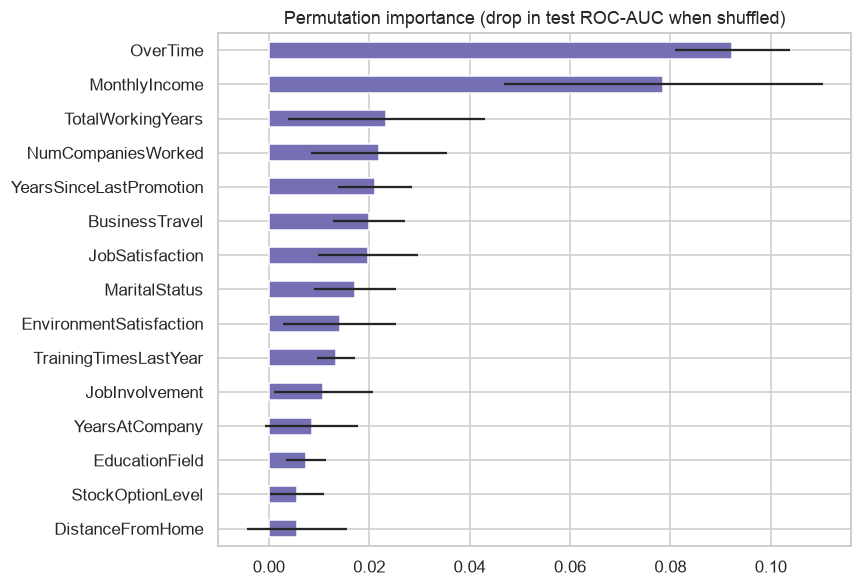

,mean_drop_auc,std
OverTime,0.0924,0.0115
MonthlyIncome,0.0786,0.0317
TotalWorkingYears,0.0234,0.0196
NumCompaniesWorked,0.0220,0.0136
YearsSinceLastPromotion,0.0212,0.0074
BusinessTravel,0.0199,0.0072
JobSatisfaction,0.0197,0.0100
MaritalStatus,0.0172,0.0082
EnvironmentSatisfaction,0.0141,0.0113
TrainingTimesLastYear,0.0134,0.0038


In [24]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=30, random_state=SEED, n_jobs=-1)
perm_s = (pd.DataFrame({"mean_drop_auc": perm.importances_mean, "std": perm.importances_std},
                       index=X_test.columns)
            .sort_values("mean_drop_auc", ascending=False))
perm_s.head(15).round(4).to_csv(OUT / "permutation_importance.csv")

fig, ax = plt.subplots(figsize=(8, 5.5))
perm_s.head(15)[::-1]["mean_drop_auc"].plot.barh(xerr=perm_s.head(15)[::-1]["std"], ax=ax, color="#7570b3")
ax.set_title("Permutation importance (drop in test ROC-AUC when shuffled)")
plt.tight_layout(); plt.savefig(OUT / "10_permutation_importance.png"); plt.show()
perm_s.head(15).round(4)

In [25]:
# Cross-check with a different model family: the tuned Random Forest's own importances
rf = searches["Random Forest"].best_estimator_
rf_imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=feat_names).sort_values(ascending=False)
rf_imp.head(12).round(3)

YearsPerCompany         0.126
MonthlyIncome           0.076
TotalWorkingYears       0.071
OverTime_Yes            0.066
YearsAtCompany          0.060
Age                     0.056
YearsWithCurrManager    0.051
AvgSatisfaction         0.049
StockOptionLevel        0.045
JobLevel                0.039
TenureRatio             0.030
YearsInCurrentRole      0.024
dtype: float64

**Top attrition drivers.** These are the drivers that the coefficients, the permutation importance and the Random Forest agree on.

1. **Overtime** is the strongest driver in every view. It has the largest coefficient (odds ratio **3.4**, meaning the odds of leaving more than triple) and the largest permutation importance (test AUC drops by 0.09 when it is shuffled).
2. **Pay** is second in permutation importance (AUC drop about 0.08). `MonthlyIncome` feeds both the raw income column and the engineered `IncomeVsLevel` feature, so its effect is spread across several coefficients. That's why it looks smaller in the coefficient chart than in the permutation chart.
3. **Early career and job hopping:**
   - Fewer `TotalWorkingYears` and a younger `Age` both raise risk (odds ratio about 0.75-0.78 per standard deviation).
   - Low `YearsPerCompany` (frequent moves) is the Random Forest's top feature and has an odds ratio of 0.60.
4. **Stalled promotions:** at the same tenure, each extra standard deviation of `YearsSinceLastPromotion` raises the odds about **1.65x**.
5. **Travel and commute:** non-travellers have about half the odds of leaving (0.49). Frequent travellers have 1.56x the odds, and `DistanceFromHome` adds 1.33x per standard deviation.
6. **Low engagement:** `JobSatisfaction`, `EnvironmentSatisfaction`, `JobInvolvement` and the combined `AvgSatisfaction` all lower the odds as they rise.
7. **Role and personal profile:** **Laboratory Technicians** (1.8x) and **Sales Representatives** (1.4x) are higher risk, and Research & Development and Research Director roles are lower. Single employees carry more risk than married or divorced ones.
8. **Protective factor:** more `YearsWithCurrManager` lowers the odds (0.75). A stable relationship with a manager seems to keep people.

*Caveat:* these are associations, not proven causes. For example, single employees are also younger and earn less on average. The drivers tell HR **where to look**, and controlled interventions would confirm what actually works.

## 9. Save the final model

In [26]:
# The whole pipeline (feature engineering + encoding + scaling + model) goes in one file,
# so it can score raw HR rows directly.
joblib.dump(final_model, "model.pkl")

meta = {
    "model": final_name,
    "best_params": {k.replace("clf__", ""): v for k, v in searches[final_name].best_params_.items()},
    "decision_threshold": round(best_t, 2),
    "test_metrics_at_threshold": {k: round(float(v), 3) for k, v in
                                  thr_table.loc[f"tuned {best_t:.2f}", ["Precision", "Recall", "F1"]].items()},
    "test_roc_auc": round(float(roc_auc_score(y_test, p_test)), 3),
    "input_columns": list(X_raw.columns),
}
Path("model_metadata.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2)[:600], "...")

{
  "model": "Logistic Regression",
  "best_params": {
    "C": 0.1,
    "penalty": "l2"
  },
  "decision_threshold": 0.68,
  "test_metrics_at_threshold": {
    "Precision": 0.575,
    "Recall": 0.489,
    "F1": 0.529
  },
  "test_roc_auc": 0.801,
  "input_columns": [
    "Age",
    "BusinessTravel",
    "DailyRate",
    "Department",
    "DistanceFromHome",
    "Education",
    "EducationField",
    "EmployeeCount",
    "EmployeeNumber",
    "EnvironmentSatisfaction",
    "Gender",
    "HourlyRate",
    "JobInvolvement",
    "JobLevel",
    "JobRole",
    "JobSatisfaction",
    "MaritalStatus ...


In [27]:
# Sanity check: reload from disk and score a few raw test rows
loaded = joblib.load("model.pkl")
check = X_test.head(5).copy()
check["leave_probability"] = loaded.predict_proba(check)[:, 1].round(3)
check["flag"] = (check["leave_probability"] >= meta["decision_threshold"]).map({True: "AT RISK", False: "-"})
check["actual"] = y_test.head(5).map({1: "Left", 0: "Stayed"}).values
assert np.allclose(loaded.predict_proba(X_test)[:, 1], p_test)
check[["Age", "JobRole", "OverTime", "MonthlyIncome", "leave_probability", "flag", "actual"]]

,Age,JobRole,OverTime,MonthlyIncome,leave_probability,flag,actual
1061,24,Sales Representative,No,2033,0.464,-,Stayed
891,44,Research Scientist,No,2011,0.050,-,Stayed
456,31,Manager,No,11557,0.418,-,Stayed
922,44,Manager,No,19190,0.036,-,Stayed
69,36,Research Scientist,Yes,3388,0.629,-,Left


## 10. Summary and recommendations

**Results**
- Dataset: 1,470 employees, 35 columns, no missing values, 16.1% attrition (imbalanced 5:1).
- Imbalance handling raised recall at 0.5 from 0.47 to about 0.74, but made the default threshold unsuitable. Per-model threshold tuning on out-of-fold predictions fixed this.
- Five tuned models were compared. **Logistic Regression** and **SVM** tied on cross-validation. Logistic Regression was chosen for explainability, and on the test set it gave **F1 0.53, ROC-AUC 0.80 and PR-AUC 0.57** (random = 0.16). It was saved as `model.pkl`, with the tuned threshold (0.68) stored in `model_metadata.json`.

**Recommendations for HR**
1. **Monitor and cap overtime.** It is the strongest driver. Track overtime per team and redistribute workload or add headcount where it is chronic.
2. **Review pay for junior staff and check promotion timelines.** Low-income, early-career employees and those passed over for promotion leave most. Benchmark job-level-1 pay, and flag anyone with no promotion in 3 or more years for a career conversation.
3. **Act on low engagement scores.** Use the satisfaction and involvement surveys as an early warning, and follow up with a manager conversation when a score drops to 1 or 2.
4. **Focus retention programmes on Sales Representatives and Lab Technicians**, the two highest-risk roles. Look at career paths, incentives and workload for these roles.
5. **Reduce travel and commute strain** with rotation of travel-heavy assignments and remote or hybrid options for long-distance commuters.
6. **Use the model as a ranked watch-list, not a verdict.** Score employees quarterly, share the top-risk list with HR business partners, and track whether interventions reduce actual attrition.

**Limitations and next steps**
- The dataset is small (237 leavers) and fictional (created by IBM data scientists), so results should be re-validated on real company data.
- There's no time dimension. A survival model (time-to-exit) would answer *when* someone may leave, not just *whether*.
- Adding SHAP explanations per employee would help HR understand *why* each person is flagged.